In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory


# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!apt-get update -qq && apt-get install -y espeak-ng -qq
!pip install -q phonemizer transformers

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [3]:
# =============================================================================
# Phoneme-Level Error Detection - v8 (CONTROL-BASELINE labeling)
# =============================================================================
# Fixes the "control samples show many errors" problem.
#
# THE PROBLEM (v5): labeling used a percentile split over ALL phonemes, so a
# fixed fraction was always "error" - including healthy control phonemes. At
# inference, control recordings then looked full of errors, which is wrong.
#
# v8 FIX - control is the healthy baseline:
#   - EVERY control phoneme is labeled CORRECT (0) and INCLUDED in training as
#     a correct example. Control anchors what "correct" sounds like.
#   - Each dysarthric phoneme is compared to its MATCHED control phoneme; only
#     dysarthric phonemes whose deviation is in the top ERROR_PERCENTILE% of the
#     DYSARTHRIC distance distribution are labeled ERROR (1). Well-produced
#     dysarthric phonemes (close to control) are correctly labeled CORRECT.
#   - The error threshold is computed ONLY over dysarthric distances, so control
#     is never forced into the error class.
#
# EXPECTED EFFECT: control recordings should now come back mostly "ok" at
# inference, and the model learns "error = deviates from the healthy reference"
# with control explicitly defining the correct baseline.
#
# Retains from v5: align to control-transcript target, mel normalization,
# no-leakage split, fast cuDNN LSTM, count-filtered report, espeak CLI.
#
# SETUP cell (run first, fresh kernel):
#   !apt-get update -qq && apt-get install -y espeak-ng -qq
#   !pip install -q transformers
#   Enable: Settings -> Accelerator -> GPU, Settings -> Internet -> On
# =============================================================================

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # silence the harmless TF layout-optimizer noise

import os
import json
import warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import librosa
import torch
import torchaudio
from tqdm.auto import tqdm

# -----------------------------------------------------------------------------
# CONFIG
# -----------------------------------------------------------------------------
TRANSCRIPTS_CSV = (
    "/kaggle/input/datasets/induwaragayashan/transcripts-uaspeech/"
    "dysarthric_control_transcripts.csv"
)
WORK_DIR = "/kaggle/working"
DATASET_NPZ = os.path.join(WORK_DIR, "phoneme_dataset.npz")
MODEL_PATH = os.path.join(WORK_DIR, "phoneme_error_model.keras")

SAMPLE_RATE = 16000
N_MELS = 64
FIXED_FRAMES = 32
CONTEXT_PAD_SEC = 0.02
TRIM_TOP_DB = 20

In [4]:
# ---------------------------------------------------------------------------
# v8 CONTROL-BASELINE LABELING (fixes "control samples show many errors")
# ---------------------------------------------------------------------------
# The problem with v5's percentile labeling: it forced a fixed fraction of ALL
# phonemes to be "error", so even healthy control phonemes got labeled error.
# At inference, control recordings then looked full of errors.
#
# v8 changes the philosophy:
#   - EVERY CONTROL phoneme is labeled CORRECT (0) by definition. The control
#     is the healthy reference - it anchors what "correct" sounds like, and it
#     is included in the training set as correct examples.
#   - Each DYSARTHRIC phoneme is compared to its MATCHED control phoneme (same
#     word, same position). If the dysarthric production deviates a lot from
#     its control (distance above ERROR_DISTANCE_CUTOFF), label it ERROR (1);
#     otherwise CORRECT (0) - a well-produced dysarthric phoneme is correct.
#
# The cutoff is chosen data-drivenly from the DYSARTHRIC distance distribution
# (top ERROR_PERCENTILE% of dysarthric deviations = error), so we don't hard-
# code an absolute number, but control is never forced into the error class.
ERROR_PERCENTILE = 30      # top X% most-deviant DYSARTHRIC phonemes -> error

# Only report per-phoneme error rates for phonemes seen at least this many times
MIN_PHONEME_COUNT = 100

LIMIT_ROWS = None          # int for a trial run, None for full dataset
MIN_ALIGN_SCORE = 0.0
REBUILD_DATASET = True

BATCH_SIZE = 32
EPOCHS = 30
RANDOM_STATE = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
# =============================================================================
# PART A - ALIGNMENT MODEL + SELF-CHECK
# =============================================================================
import subprocess
from transformers import Wav2Vec2ForCTC, Wav2Vec2CTCTokenizer

MODEL_NAME = "facebook/wav2vec2-lv-60-espeak-cv-ft"
print("Loading alignment model...")
TOKENIZER = Wav2Vec2CTCTokenizer.from_pretrained(MODEL_NAME)
ALIGN_MODEL = Wav2Vec2ForCTC.from_pretrained(MODEL_NAME).to(device)
ALIGN_MODEL.eval()
BLANK_ID = TOKENIZER.pad_token_id
_VOCAB = TOKENIZER.get_vocab()


def word_to_phonemes(word):
    """
    Get IPA phonemes for a word using the espeak-ng CLI directly (subprocess).
    This deliberately AVOIDS the `phonemizer` Python package, whose library-copy
    mechanism fails on Kaggle because /tmp is mounted noexec ("failed to map
    segment from shared object"). The CLI runs the installed binary in place.
    Verified: espeak-ng 1.50 IPA output matches this model's vocabulary exactly.
    """
    out = subprocess.run(
        ["espeak-ng", "-q", "--ipa", "-v", "en-us", word.strip()],
        capture_output=True, text=True,
    ).stdout.strip()
    # Strip stress/length marks that aren't in the model vocab
    out = out.replace("ˈ", "").replace("ˌ", "").replace("ː", "")
    return [ch for ch in out if ch.strip()]


def transcript_to_phonemes(transcript):
    phones = []
    for w in transcript.strip().split():
        phones.extend(word_to_phonemes(w))
    return phones


# --- SELF-CHECK: fail loudly NOW if espeak CLI is broken ---------------------
print("\n[self-check] Testing espeak-ng CLI on the word 'well'...")
_test = word_to_phonemes("well")
print(f"[self-check] 'well' -> {_test}")
if not _test:
    raise RuntimeError(
        "espeak-ng CLI produced NO phonemes. Install it first:\n"
        "  !apt-get update -qq && apt-get install -y espeak-ng -qq"
    )
_in_vocab = [p for p in _test if p in _VOCAB]
print(f"[self-check] phonemes present in model vocab: {_in_vocab}")
if not _in_vocab:
    raise RuntimeError(
        "Phonemes produced but NONE are in the model vocabulary. "
        "The espeak IPA symbols don't match the model's phone set."
    )
print("[self-check] OK - alignment inputs look valid.\n")


def _emission(waveform):
    with torch.inference_mode():
        logits = ALIGN_MODEL(waveform.to(device)).logits
        return torch.log_softmax(logits, dim=-1)


def align_phonemes(audio_path, transcript):
    waveform, _ = librosa.load(audio_path, sr=SAMPLE_RATE)
    waveform, _ = librosa.effects.trim(waveform, top_db=TRIM_TOP_DB)
    if len(waveform) < SAMPLE_RATE * 0.05:
        raise ValueError("audio too short after trimming (<50ms)")
    waveform_t = torch.tensor(waveform).unsqueeze(0)

    phonemes = transcript_to_phonemes(transcript)
    tokens, kept = [], []
    for p in phonemes:
        if p in _VOCAB:
            tokens.append(_VOCAB[p]); kept.append(p)
    if not tokens:
        raise ValueError(f"no valid phonemes for transcript '{transcript}'")

    emission = _emission(waveform_t)
    targets = torch.tensor([tokens], dtype=torch.int32, device=device)
    aligned, scores = torchaudio.functional.forced_align(emission, targets, blank=BLANK_ID)
    aligned, scores = aligned[0], scores[0].exp()
    spans = torchaudio.functional.merge_tokens(aligned, scores)

    num_frames = emission.size(1)
    ratio = waveform_t.size(1) / num_frames / SAMPLE_RATE
    return [(p, float(s.start * ratio), float(s.end * ratio), float(s.score))
            for s, p in zip(spans, kept[: len(spans)])]


def crop_phoneme_mel(audio_path, start_sec, end_sec):
    y, _ = librosa.load(audio_path, sr=SAMPLE_RATE)
    s = max(0.0, start_sec - CONTEXT_PAD_SEC)
    e = end_sec + CONTEXT_PAD_SEC
    clip = y[int(s * SAMPLE_RATE): min(int(e * SAMPLE_RATE), len(y))]
    if len(clip) == 0:
        clip = np.zeros(int(0.05 * SAMPLE_RATE), dtype=np.float32)
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=clip, sr=SAMPLE_RATE, n_mels=N_MELS))
    if mel.shape[1] < FIXED_FRAMES:
        mel = np.pad(mel, ((0, 0), (0, FIXED_FRAMES - mel.shape[1])), mode="constant")
    else:
        mel = mel[:, :FIXED_FRAMES]
    return mel


def phoneme_distance(impaired_mel, control_mel):
    """Raw mean |dB| distance between impaired and matched control phoneme."""
    m = min(impaired_mel.shape[1], control_mel.shape[1])
    return float(np.mean(np.abs(impaired_mel[:, :m] - control_mel[:, :m])))

Loading alignment model...


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]


[self-check] Testing espeak-ng CLI on the word 'well'...
[self-check] 'well' -> ['w', 'ɛ', 'l']
[self-check] phonemes present in model vocab: ['w', 'ɛ', 'l']
[self-check] OK - alignment inputs look valid.



In [6]:
# =============================================================================
# PART B - BUILD DATASET (two-pass: collect distances, THEN threshold)
# =============================================================================
def build_dataset():
    df = pd.read_csv(TRANSCRIPTS_CSV)
    if LIMIT_ROWS is not None:
        df = df.head(LIMIT_ROWS)
    print(f"Building phoneme dataset from {len(df)} paired recordings...")

    mels, phon_list, scores, dists, is_control = [], [], [], [], []
    fail_reasons = Counter()
    n_failed = 0

    for _, row in tqdm(df.iterrows(), total=len(df), desc="Aligning + cropping"):
        dys_path = str(row["dysarthric_audio"])
        ctrl_path = str(row["control_audio"])
        # The control transcript (Whisper on CLEAR speech) is our best proxy for
        # the TARGET word. We align BOTH recordings to this same target so that
        # phoneme i in the dysarthric audio corresponds to phoneme i in the
        # control (same intended sound) - which is what makes the per-phoneme
        # distance label valid. We deliberately do NOT use the dysarthric
        # transcript (Whisper on GARBLED speech), which would hide the errors by
        # aligning to what was mis-produced rather than what was intended.
        target_word = str(row["control_transcript"])

        if not os.path.exists(dys_path):
            fail_reasons["dysarthric_audio missing"] += 1; n_failed += 1; continue
        if not os.path.exists(ctrl_path):
            fail_reasons["control_audio missing"] += 1; n_failed += 1; continue

        try:
            dys_align = align_phonemes(dys_path, target_word)   # dysarthric vs TARGET
            ctrl_align = align_phonemes(ctrl_path, target_word)  # control  vs TARGET
        except Exception as ex:
            fail_reasons[f"align: {type(ex).__name__}: {str(ex)[:40]}"] += 1
            n_failed += 1; continue

        if not dys_align:
            fail_reasons["empty dysarthric alignment"] += 1; n_failed += 1; continue

        try:
            # Collect DYSARTHRIC phonemes with their distance to matched control,
            # AND collect the CONTROL phonemes themselves as guaranteed-correct.
            for i, (phon, s, e, sc) in enumerate(dys_align):
                if sc < MIN_ALIGN_SCORE:
                    continue
                if i >= len(ctrl_align):
                    continue  # no matched control phoneme (length mismatch)
                _, cs, ce, csc = ctrl_align[i]

                imp_mel = crop_phoneme_mel(dys_path, s, e)
                ctrl_mel = crop_phoneme_mel(ctrl_path, cs, ce)
                d = phoneme_distance(imp_mel, ctrl_mel)

                # DYSARTHRIC example: label decided later by distance threshold
                mels.append(imp_mel)
                phon_list.append(phon)
                scores.append(sc)
                dists.append(d)
                is_control.append(0)   # 0 = dysarthric

                # CONTROL example: ALWAYS correct (healthy reference anchor)
                mels.append(ctrl_mel)
                phon_list.append(phon)
                scores.append(csc)
                dists.append(0.0)      # control has zero deviation from itself
                is_control.append(1)   # 1 = control
        except Exception as ex:
            fail_reasons[f"crop: {type(ex).__name__}"] += 1
            n_failed += 1; continue

    # ---- Report failures clearly ----
    print(f"\n{n_failed} recordings failed. Top reasons:")
    for reason, count in fail_reasons.most_common(10):
        print(f"  {count:6d}  {reason}")

    if not mels:
        raise RuntimeError(
            "No phoneme examples built at all. Check the self-check output "
            "above and the failure reasons - espeak or paths are the usual cause."
        )

    X = np.array(mels)[..., np.newaxis]
    phon_arr = np.array(phon_list)
    score_arr = np.array(scores)
    dist_arr = np.array(dists)
    ctrl_arr = np.array(is_control)

    # ---- v8 CONTROL-BASELINE LABELS ----
    # Control phonemes -> always CORRECT (0).
    # Dysarthric phonemes -> ERROR (1) if their deviation is in the top
    #   ERROR_PERCENTILE% of the DYSARTHRIC distance distribution, else CORRECT.
    # The threshold is computed ONLY over dysarthric distances, so control is
    # never dragged into the error class.
    dys_mask = ctrl_arr == 0
    dys_dists = dist_arr[dys_mask]
    cutoff = np.percentile(dys_dists, 100 - ERROR_PERCENTILE)

    y = np.zeros(len(X), dtype=int)
    # dysarthric phonemes above the cutoff = error
    y[dys_mask & (dist_arr >= cutoff)] = 1
    # (control phonemes and low-deviation dysarthric phonemes stay 0 = correct)

    n_ctrl = int(ctrl_arr.sum())
    n_dys = int((ctrl_arr == 0).sum())
    print(f"\nDysarthric deviation stats: min={dys_dists.min():.2f}, "
          f"median={np.median(dys_dists):.2f}, max={dys_dists.max():.2f}")
    print(f"Error cutoff (top {ERROR_PERCENTILE}% of dysarthric): distance >= {cutoff:.2f}")
    print(f"Control phonemes (all correct):      {n_ctrl}")
    print(f"Dysarthric phonemes:                 {n_dys}")
    print(f"  -> labeled error:                  {int((y==1).sum())}")
    print(f"  -> labeled correct:                {int((y[dys_mask]==0).sum())}")
    print(f"TOTAL: {int((y==1).sum())} error / {int((y==0).sum())} correct")

    # ---- MEL NORMALIZATION (global z-score) - helps the CNN learn ----
    mel_mean = float(X.mean())
    mel_std = float(X.std() + 1e-8)
    X = (X - mel_mean) / mel_std
    print(f"Normalized mels: mean={mel_mean:.2f}, std={mel_std:.2f}")

    np.savez_compressed(
        DATASET_NPZ, X=X, y=y, phonemes=phon_arr, scores=score_arr,
        distances=dist_arr, is_control=ctrl_arr, mel_mean=mel_mean, mel_std=mel_std,
    )
    print(f"Cached dataset -> {DATASET_NPZ}")
    return X, y, phon_arr, score_arr


if REBUILD_DATASET or not os.path.exists(DATASET_NPZ):
    X, y, phonemes, align_scores = build_dataset()
else:
    d = np.load(DATASET_NPZ, allow_pickle=True)
    X, y = d["X"], d["y"]
    phonemes = d["phonemes"] if "phonemes" in d else np.array(["?"] * len(X))
    align_scores = d["scores"] if "scores" in d else np.zeros(len(X))

assert len(X) > 0

Building phoneme dataset from 10000 paired recordings...


Aligning + cropping:   0%|          | 0/10000 [00:00<?, ?it/s]


3 recordings failed. Top reasons:
       3  align: RuntimeError: forced_align_impl, /__w/audio/audio/pyto

Dysarthric deviation stats: min=0.13, median=0.76, max=6.83
Error cutoff (top 30% of dysarthric): distance >= 1.20
Control phonemes (all correct):      49153
Dysarthric phonemes:                 49153
  -> labeled error:                  14746
  -> labeled correct:                34407
TOTAL: 14746 error / 83560 correct
Normalized mels: mean=-2.41, std=10.22
Cached dataset -> /kaggle/working/phoneme_dataset.npz


In [7]:
# =============================================================================
# PART C - TRAIN CNN-BiLSTM
# =============================================================================
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, LSTM, Dense, Bidirectional,
    TimeDistributed, Input, Dropout, BatchNormalization,
)
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

X_err_n, X_ok_n = int((y == 1).sum()), int((y == 0).sum())
print(f"\nClean dataset: {X_err_n} error, {X_ok_n} correct")
if X_err_n == 0 or X_ok_n == 0:
    raise RuntimeError("One class empty - adjust ERROR_PERCENTILE.")

# ---- SPLIT FIRST, then balance ONLY the training set ----
# (v3 balanced before splitting, which leaked upsampled duplicates into test
#  and inflated the metrics. v4 splits first so the test set stays clean.)
y_cat_all = to_categorical(y, num_classes=2)
X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    X, y_cat_all, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Upsample the minority class within the TRAINING set only
y_train_lbl = np.argmax(y_train_raw, axis=1)
X_tr_err = X_train_raw[y_train_lbl == 1]
X_tr_ok = X_train_raw[y_train_lbl == 0]
if len(X_tr_err) < len(X_tr_ok):
    X_tr_err = resample(X_tr_err, replace=True, n_samples=len(X_tr_ok), random_state=RANDOM_STATE)
else:
    X_tr_ok = resample(X_tr_ok, replace=True, n_samples=len(X_tr_err), random_state=RANDOM_STATE)

X_train = np.concatenate([X_tr_err, X_tr_ok])
y_train_bal = np.concatenate([np.ones(len(X_tr_err)), np.zeros(len(X_tr_ok))])
perm = np.random.RandomState(RANDOM_STATE).permutation(len(X_train))
X_train = X_train[perm]
y_train = to_categorical(y_train_bal[perm], num_classes=2)

print(f"Train (balanced): {X_train.shape}, Test (clean, unbalanced): {X_test.shape}")

inp = Input(shape=X_train.shape[1:])
x = Conv2D(16, (3, 3), activation="relu", padding="same")(inp)
x = BatchNormalization()(x); x = MaxPooling2D((2, 2))(x); x = Dropout(0.3)(x)
x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x); x = MaxPooling2D((2, 2))(x); x = Dropout(0.3)(x)
x = TimeDistributed(Flatten())(x)
x = Bidirectional(LSTM(128, dropout=0.3))(x)   # no recurrent_dropout -> fast cuDNN path
x = Dense(64, activation="relu")(x); x = Dropout(0.3)(x)
out = Dense(2, activation="softmax")(x)

model = Model(inp, out)
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                              restore_best_weights=True)
history = model.fit(X_train, y_train, batch_size=BATCH_SIZE, epochs=EPOCHS,
                    validation_data=(X_test, y_test), callbacks=[early_stop])
model.save(MODEL_PATH)
print(f"Saved model -> {MODEL_PATH}")


Clean dataset: 14746 error, 83560 correct
Train (balanced): (133694, 64, 32, 1), Test (clean, unbalanced): (19662, 64, 32, 1)


I0000 00:00:1784606376.748534   43569 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9132 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784606376.750696   43569 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 8, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 8, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 16, 256)        │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 415,810 (1.59 MB)

 Trainable params: 415,714 (1.59 MB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/30


E0000 00:00:1784606384.457371   43569 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


4178/4178 ━━━━━━━━━━━━━━━━━━━━ 58s 12ms/step - accuracy: 0.6495 - loss: 0.6257 - val_accuracy: 0.6164 - val_loss: 0.6158
Epoch 2/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 51s 12ms/step - accuracy: 0.6842 - loss: 0.5899 - val_accuracy: 0.6045 - val_loss: 0.6031
Epoch 3/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 51s 12ms/step - accuracy: 0.6987 - loss: 0.5725 - val_accuracy: 0.6336 - val_loss: 0.5721
Epoch 4/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 51s 12ms/step - accuracy: 0.7079 - loss: 0.5601 - val_accuracy: 0.6376 - val_loss: 0.5812
Epoch 5/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 51s 12ms/step - accuracy: 0.7136 - loss: 0.5545 - val_accuracy: 0.6638 - val_loss: 0.5592
Epoch 6/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 50s 12ms/step - accuracy: 0.7174 - loss: 0.5456 - val_accuracy: 0.6891 - val_loss: 0.5029
Epoch 7/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 51s 12ms/step - accuracy: 0.7203 - loss: 0.5396 - val_accuracy: 0.7199 - val_loss: 0.4786
Epoch 8/30
4178/4178 ━━━━━━━━━━━━━━━━━━━━ 50s 12ms/step - accuracy: 0.7251 - loss: 0.53


Test accuracy: 0.7199
615/615 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
              precision    recall  f1-score   support

     Correct       0.94      0.71      0.81     16713
       Error       0.32      0.75      0.45      2949

    accuracy                           0.72     19662
   macro avg       0.63      0.73      0.63     19662
weighted avg       0.85      0.72      0.76     19662



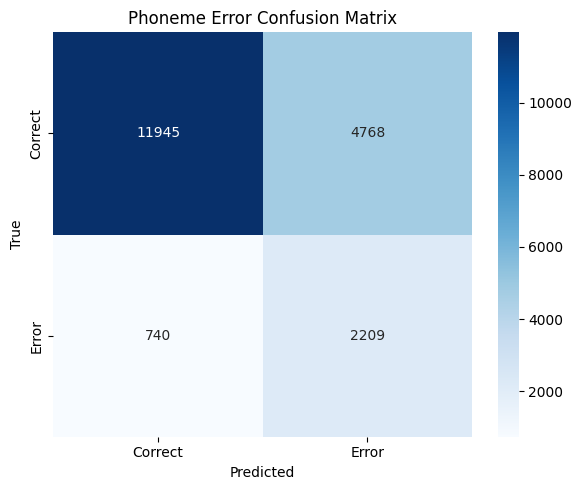

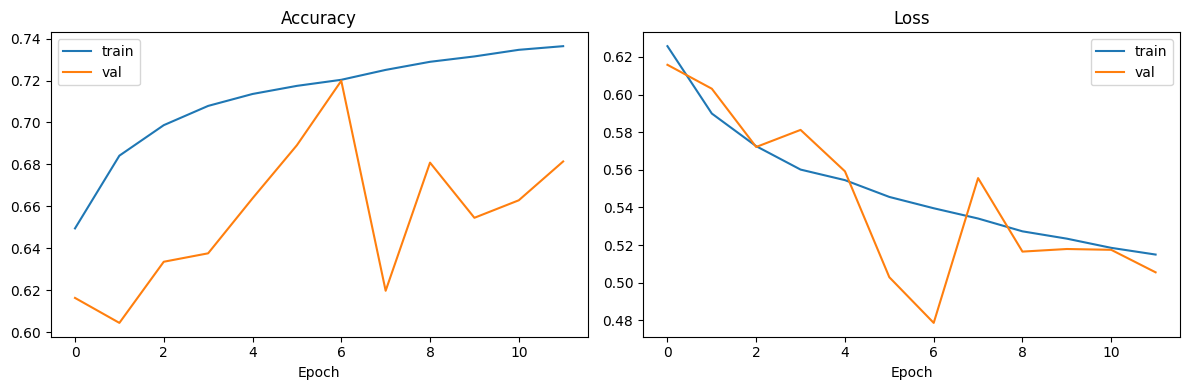

3073/3073 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step

Top error-prone phonemes (only those with >= 100 occurrences):
phoneme  count  error_rate
      ɾ    598    0.508361
      ɚ   2062    0.497090
      ŋ    674    0.464392
      ə   3594    0.455760
      ʊ   4122    0.442989
      z   1744    0.440940
      θ    706    0.437677
      v   1270    0.434646
      t   5286    0.421112
      l   4562    0.413415
      n   4802    0.408788
      ɪ   8534    0.400516
      ʒ   1124    0.395907
      ɹ   4352    0.391085
      m   2646    0.382842

(3 rare phonemes below the count threshold were excluded as unreliable.)


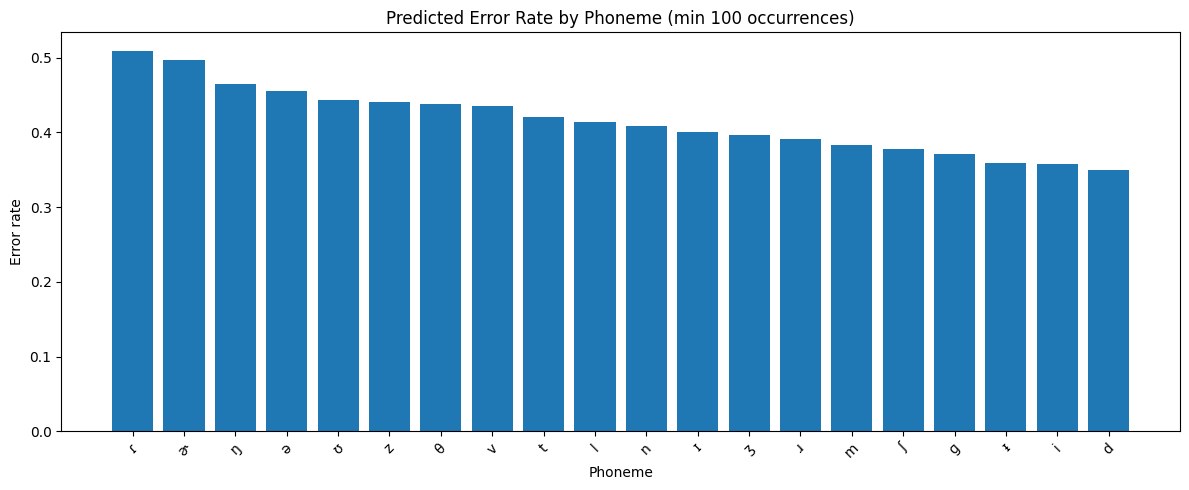


Done. Outputs in /kaggle/working/


In [8]:
# =============================================================================
# PART D - EVALUATION + PER-PHONEME ANALYSIS
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}")
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
print(classification_report(y_true, y_pred, target_names=["Correct", "Error"]))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Correct", "Error"], yticklabels=["Correct", "Error"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Phoneme Error Confusion Matrix")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "confusion_matrix.png")); plt.show()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "training_history.png")); plt.show()

full_pred = np.argmax(model.predict(X), axis=1)
per_phon = {}
for ph, pred in zip(phonemes, full_pred):
    per_phon.setdefault(str(ph), []).append(pred)
rows = [{"phoneme": ph, "count": len(p), "error_rate": float(np.mean(p))}
        for ph, p in per_phon.items()]
per_phon_df = pd.DataFrame(rows).sort_values("error_rate", ascending=False)

# Filter out statistically-meaningless tiny-count phonemes (e.g. ʔ with n=12).
# Only phonemes seen >= MIN_PHONEME_COUNT times are trustworthy / reportable.
reliable_df = per_phon_df[per_phon_df["count"] >= MIN_PHONEME_COUNT].copy()
reliable_df.to_csv(os.path.join(WORK_DIR, "per_phoneme_error_rates.csv"), index=False)

print(f"\nTop error-prone phonemes (only those with >= {MIN_PHONEME_COUNT} occurrences):")
print(reliable_df.head(15).to_string(index=False))
print(f"\n({len(per_phon_df) - len(reliable_df)} rare phonemes below the count "
      f"threshold were excluded as unreliable.)")

top = reliable_df.head(20)
plt.figure(figsize=(12, 5))
plt.bar(top["phoneme"], top["error_rate"])
plt.title(f"Predicted Error Rate by Phoneme (min {MIN_PHONEME_COUNT} occurrences)")
plt.ylabel("Error rate"); plt.xlabel("Phoneme"); plt.xticks(rotation=45)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "per_phoneme_error_rates.png")); plt.show()

print("\nDone. Outputs in /kaggle/working/")

In [11]:
# =============================================================================
# Phoneme-Level Error Detection - INFERENCE for the v8 CONTROL-BASELINE model
# =============================================================================
# v8 was trained with control phonemes as guaranteed-correct examples and
# dysarthric phonemes labeled error only when they deviate from their control.
# Input is ONE mel per phoneme (64 x FIXED_FRAMES), same as v5 - so inference
# is one segment per phoneme (NOT sub-windows like v7).
#
# Includes the trim-once timebase fix so phoneme bands line up on the waveform,
# audio playback, and a CONTROL-vs-DYSARTHRIC validation that checks the exact
# thing v8 was built to fix: control recordings should now come back mostly OK.
#
# REQUIREMENTS:
#   !apt-get update -qq && apt-get install -y espeak-ng -qq
#   !pip install -q transformers
#   Trained model + dataset npz (for normalization stats):
#     /kaggle/working/phoneme_error_model.keras
#     /kaggle/working/phoneme_dataset.npz
# =============================================================================

import os
import subprocess
import numpy as np
import librosa
import torch
import torchaudio
import matplotlib.pyplot as plt
import pandas as pd
from transformers import Wav2Vec2ForCTC, Wav2Vec2CTCTokenizer
from tensorflow.keras.models import load_model

# -----------------------------------------------------------------------------
# CONFIG - MUST MATCH v8 TRAINING
# -----------------------------------------------------------------------------
MODEL_PATH = "/kaggle/working/phoneme_error_model.keras"
DATASET_NPZ = "/kaggle/working/phoneme_dataset.npz"
TRANSCRIPTS_CSV = (
    "/kaggle/input/datasets/induwaragayashan/transcripts-uaspeech/"
    "dysarthric_control_transcripts.csv"
)

SAMPLE_RATE = 16000
N_MELS = 64
FIXED_FRAMES = 32          # must match v8 training
CONTEXT_PAD_SEC = 0.02
TRIM_TOP_DB = 20

# Decision threshold on per-phoneme error probability.
# 0.40 = screening (catch more errors); 0.45 = balanced; 0.50 = higher precision.
ERROR_THRESHOLD = 0.50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------------------------------------------------------
# Load trained classifier + normalization stats
# -----------------------------------------------------------------------------
print("Loading trained v8 model + normalization stats...")
CLF = load_model(MODEL_PATH)
_d = np.load(DATASET_NPZ, allow_pickle=True)
MEL_MEAN = float(_d["mel_mean"]) if "mel_mean" in _d else 0.0
MEL_STD = float(_d["mel_std"]) if "mel_std" in _d else 1.0
print(f"  mel_mean={MEL_MEAN:.2f}, mel_std={MEL_STD:.2f}, threshold={ERROR_THRESHOLD}")

# -----------------------------------------------------------------------------
# Alignment model (same as training)
# -----------------------------------------------------------------------------
ALIGN_NAME = "facebook/wav2vec2-lv-60-espeak-cv-ft"
print("Loading alignment model...")
TOKENIZER = Wav2Vec2CTCTokenizer.from_pretrained(ALIGN_NAME)
ALIGN_MODEL = Wav2Vec2ForCTC.from_pretrained(ALIGN_NAME).to(device)
ALIGN_MODEL.eval()
BLANK_ID = TOKENIZER.pad_token_id
_VOCAB = TOKENIZER.get_vocab()


# -----------------------------------------------------------------------------
# Phonemes via espeak-ng CLI (same as training)
# -----------------------------------------------------------------------------
def word_to_phonemes(word):
    out = subprocess.run(
        ["espeak-ng", "-q", "--ipa", "-v", "en-us", word.strip()],
        capture_output=True, text=True,
    ).stdout.strip()
    out = out.replace("ˈ", "").replace("ˌ", "").replace("ː", "")
    return [ch for ch in out if ch.strip()]


def transcript_to_phonemes(transcript):
    phones = []
    for w in transcript.strip().split():
        phones.extend(word_to_phonemes(w))
    return phones


def _emission(waveform):
    with torch.inference_mode():
        logits = ALIGN_MODEL(waveform.to(device)).logits
        return torch.log_softmax(logits, dim=-1)


def load_and_trim(audio_path):
    """Load + trim ONCE so alignment timestamps and the plot share one timebase."""
    y, _ = librosa.load(audio_path, sr=SAMPLE_RATE)
    y, _ = librosa.effects.trim(y, top_db=TRIM_TOP_DB)
    return y


def align_on_wave(waveform, transcript):
    if len(waveform) < SAMPLE_RATE * 0.05:
        raise ValueError("Audio too short after trimming.")
    waveform_t = torch.tensor(waveform).unsqueeze(0)
    phonemes = transcript_to_phonemes(transcript)
    tokens, kept = [], []
    for p in phonemes:
        if p in _VOCAB:
            tokens.append(_VOCAB[p]); kept.append(p)
    if not tokens:
        raise ValueError(f"No valid phonemes for '{transcript}'.")

    emission = _emission(waveform_t)
    targets = torch.tensor([tokens], dtype=torch.int32, device=device)
    aligned, scores = torchaudio.functional.forced_align(emission, targets, blank=BLANK_ID)
    aligned, scores = aligned[0], scores[0].exp()
    spans = torchaudio.functional.merge_tokens(aligned, scores)
    num_frames = emission.size(1)
    ratio = len(waveform) / num_frames / SAMPLE_RATE
    return [(p, float(s.start * ratio), float(s.end * ratio), float(s.score))
            for s, p in zip(spans, kept[: len(spans)])]


def crop_mel_from_wave(waveform, start_sec, end_sec):
    """One mel per phoneme (64 x FIXED_FRAMES), matching v8 training."""
    s = max(0.0, start_sec - CONTEXT_PAD_SEC)
    e = end_sec + CONTEXT_PAD_SEC
    clip = waveform[int(s * SAMPLE_RATE): min(int(e * SAMPLE_RATE), len(waveform))]
    if len(clip) == 0:
        clip = np.zeros(int(0.05 * SAMPLE_RATE), dtype=np.float32)
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=clip, sr=SAMPLE_RATE, n_mels=N_MELS))
    if mel.shape[1] < FIXED_FRAMES:
        mel = np.pad(mel, ((0, 0), (0, FIXED_FRAMES - mel.shape[1])), mode="constant")
    else:
        mel = mel[:, :FIXED_FRAMES]
    return mel


# -----------------------------------------------------------------------------
# MAIN PREDICTION
# -----------------------------------------------------------------------------
def predict_on_file(audio_path, target_word, show_plot=True, play_audio=True, verbose=True):
    if not os.path.exists(audio_path):
        raise FileNotFoundError(audio_path)

    wave = load_and_trim(audio_path)
    segments = align_on_wave(wave, target_word)
    if not segments:
        if verbose:
            print("No phonemes could be aligned. Check the word / recording.")
        return []

    mels = np.stack([crop_mel_from_wave(wave, s, e) for _, s, e, _ in segments])
    mels = mels[..., np.newaxis]
    mels = (mels - MEL_MEAN) / MEL_STD
    probs = CLF.predict(mels, verbose=0)[:, 1]

    results = []
    if verbose:
        print(f"\n=== Analysis of '{target_word}' (v8) ===")
        print(f"{'phoneme':>8} | {'time (s)':>13} | {'verdict':>8} | P(error)")
        print("-" * 48)
    for (phon, s, e, align_sc), p in zip(segments, probs):
        verdict = "ERROR" if p >= ERROR_THRESHOLD else "ok"
        mark = "  <==" if verdict == "ERROR" else ""
        if verbose:
            print(f"{phon:>8} | {s:5.2f} - {e:5.2f} | {verdict:>8} | {p:.2f}{mark}")
        results.append({"phoneme": phon, "start": s, "end": e,
                        "verdict": verdict, "error_prob": float(p),
                        "align_score": align_sc})

    n_err = sum(1 for r in results if r["verdict"] == "ERROR")
    if verbose:
        print("-" * 48)
        print(f"{n_err}/{len(results)} phonemes flagged as errors "
              f"(threshold={ERROR_THRESHOLD})")
        dur = len(wave) / SAMPLE_RATE
        print(f"(audio duration {dur:.2f}s; last phoneme ends {segments[-1][2]:.2f}s)")
        if play_audio:
            _play(wave)
        if show_plot:
            _plot(wave, results, target_word)
    return results


def _play(wave):
    try:
        from IPython.display import Audio, display
        print("\n▶ Play the recording:")
        display(Audio(wave, rate=SAMPLE_RATE))
    except Exception as ex:
        print(f"(Could not embed audio player: {ex})")


def _plot(wave, results, target_word):
    dur = len(wave) / SAMPLE_RATE
    t = np.linspace(0, dur, len(wave))
    plt.figure(figsize=(13, 4))
    plt.plot(t, wave, color="gray", linewidth=0.7)
    for r in results:
        color = "red" if r["verdict"] == "ERROR" else "green"
        plt.axvspan(r["start"], r["end"], color=color, alpha=0.18)
        mid = (r["start"] + r["end"]) / 2
        plt.text(mid, max(wave) * 0.8, r["phoneme"], ha="center", fontsize=12,
                 color="darkred" if r["verdict"] == "ERROR" else "darkgreen",
                 fontweight="bold")
    plt.title(f"'{target_word}'  -  red = predicted error, green = ok  (v8)")
    plt.xlabel("Time (s)"); plt.ylabel("Amplitude")
    plt.xlim(0, dur)
    plt.tight_layout(); plt.show()


# -----------------------------------------------------------------------------
# OPTION 3: Test on an existing UASpeech file (no mic needed)
# -----------------------------------------------------------------------------
def test_on_dataset_file(row_index=None, random_row=False, dysarthric=True):
    df = pd.read_csv(TRANSCRIPTS_CSV)
    if random_row:
        row = df.sample(1).iloc[0]
    elif row_index is not None:
        row = df.iloc[row_index]
    else:
        row = df.iloc[0]

    target_word = str(row["control_transcript"])
    if dysarthric:
        audio_path = str(row["dysarthric_audio"]); tag = "DYSARTHRIC"
    else:
        audio_path = str(row["control_audio"]); tag = "CONTROL"

    print(f"[{tag}] file: {audio_path}")
    print(f"[{tag}] target word: {target_word}")
    if not os.path.exists(audio_path):
        print(f"File not found: {audio_path}")
        return []
    return predict_on_file(audio_path, target_word)


def compare_dysarthric_vs_control(row_index=0):
    """Control vs dysarthric of the SAME word - the key v8 sanity check."""
    print("=" * 55)
    print("CONTROL (healthy) - v8 should now show MOSTLY OK:")
    print("=" * 55)
    test_on_dataset_file(row_index=row_index, random_row=False, dysarthric=False)
    print("\n" + "=" * 55)
    print("DYSARTHRIC (same word) - expect more errors:")
    print("=" * 55)
    test_on_dataset_file(row_index=row_index, random_row=False, dysarthric=True)


# -----------------------------------------------------------------------------
# v8 VALIDATION: does control really come back mostly-correct now?
# -----------------------------------------------------------------------------
def validate_control_vs_dysarthric(n=50):
    """
    Run inference on n control and n dysarthric recordings and report the mean
    fraction of phonemes flagged as errors in each group. This directly tests
    the thing v8 was built to fix: control error-rate should be LOW, dysarthric
    error-rate should be clearly HIGHER.
    """
    df = pd.read_csv(TRANSCRIPTS_CSV).sample(n, random_state=0)
    ctrl_rates, dys_rates = [], []

    for _, row in df.iterrows():
        target = str(row["control_transcript"])
        cpath, dpath = str(row["control_audio"]), str(row["dysarthric_audio"])
        try:
            if os.path.exists(cpath):
                r = predict_on_file(cpath, target, show_plot=False,
                                    play_audio=False, verbose=False)
                if r:
                    ctrl_rates.append(np.mean([x["verdict"] == "ERROR" for x in r]))
            if os.path.exists(dpath):
                r = predict_on_file(dpath, target, show_plot=False,
                                    play_audio=False, verbose=False)
                if r:
                    dys_rates.append(np.mean([x["verdict"] == "ERROR" for x in r]))
        except Exception:
            continue

    print("\n===== v8 CONTROL-BASELINE VALIDATION =====")
    print(f"Recordings tested: {len(ctrl_rates)} control, {len(dys_rates)} dysarthric")
    print(f"Mean phoneme error-rate  -  CONTROL:    {np.mean(ctrl_rates):.1%}")
    print(f"Mean phoneme error-rate  -  DYSARTHRIC: {np.mean(dys_rates):.1%}")
    gap = np.mean(dys_rates) - np.mean(ctrl_rates)
    print(f"Separation (dysarthric - control):      {gap:+.1%}")
    if np.mean(ctrl_rates) < 0.25 and gap > 0.10:
        print("=> GOOD: control is mostly-correct and clearly separated from dysarthric.")
    elif np.mean(ctrl_rates) >= 0.25:
        print("=> Control still shows many errors - raise ERROR_THRESHOLD or check labeling.")
    else:
        print("=> Weak separation - the model may not distinguish the two groups well.")


Loading trained v8 model + normalization stats...
  mel_mean=-2.41, mel_std=10.22, threshold=0.5
Loading alignment model...


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

[CONTROL] file: /kaggle/input/datasets/aryashah2k/noise-reduced-uaspeech-dysarthria-dataset/noisereduced-uaspeech-control/CM05/CM05_B2_C9_M8.wav
[CONTROL] target word: shift

=== Analysis of 'shift' (v8) ===
 phoneme |      time (s) |  verdict | P(error)
------------------------------------------------
       ʃ |  0.04 -  0.06 |       ok | 0.04
       ɪ |  0.12 -  0.14 |       ok | 0.50
       f |  0.26 -  0.28 |       ok | 0.31
       t |  0.36 -  0.38 |       ok | 0.30
------------------------------------------------
0/4 phonemes flagged as errors (threshold=0.5)
(audio duration 1.25s; last phoneme ends 0.38s)

▶ Play the recording:


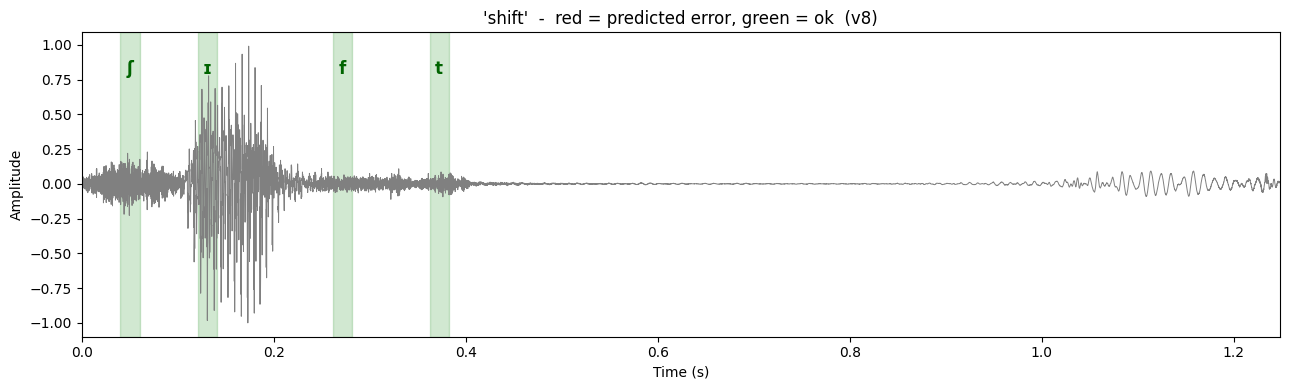

In [23]:
if __name__ == "__main__":
    # The key v8 check - does control come back mostly OK now?
    #validate_control_vs_dysarthric(n=50)

    # Inspect a single side-by-side example:
    # compare_dysarthric_vs_control(row_index=0)

    # Test a random dysarthric file with full output + plot + audio:
    test_on_dataset_file(random_row=True, dysarthric=False)

    # Your own uploaded wav:
    # predict_on_file("/kaggle/working/my_recording.wav", "well")